# 2. Write your own SVD

## What this notebook is about

Here you write an SVD yourself. We start with a method that looks perfectly good: six
lines long, fast, and correct on ordinary matrices. The checker shows that it fails on two
of the test matrices. You will see what goes wrong and why, and then fix it. That loop
(write, check, understand the failure, fix) is how you will work on your own methods, so
the notebook goes through it slowly.

## What you will learn

1. The exact rules your function must follow (the *contract*).
2. How to smoke-test a function on one matrix before the full check.
3. Why a small reconstruction error alone does not prove an SVD is correct.
4. How to look at a failing case next to the reference.
5. How to fix the method, and how wide matrices are handled.
6. How to write your own method in a cell, then save it to a file and check it from the
   command line.

## Words used here

| Word | Meaning |
| --- | --- |
| **Gram matrix** | AᴴA, an n × n matrix. Its eigenvalues are the squared singular values of A, its eigenvectors are the right singular vectors V |
| **condition number** | σ₁ / σ_min, the ratio of the largest to the smallest singular value. Large means some directions of A are almost lost, and those are hard to compute |
| **orthonormal** | columns of length 1 that are perpendicular to each other: UᴴU = I |
| **eps** | the precision of the number type: about 2.2e-16 for float64, 1.2e-7 for float32 |

Takes about a minute on a CPU. Uses the GPU when there is one. Text version with more
background: [tutorial 2](../docs/tutorials/02-write-your-own-svd.md).

## Setup

**What this cell does:** it finds the repository folder (so the notebook works from any
working directory), makes `svdlab` importable even if you have not installed it with pip,
and chooses where to compute: `DEVICE` is `'cuda'` when PyTorch sees a GPU and `'cpu'`
otherwise. To stay on the CPU even with a GPU present, set `USE_GPU = False`.

**What you should see:** one line with the PyTorch version and the chosen device. If you
get `ModuleNotFoundError`, the notebook kernel is not the Python environment where you ran
`pip install -e '.[laboratory]'`. Choose that environment as the kernel and run the cell
again.

In [1]:
# Setup: find the repository, choose the device. Run this cell first.
from pathlib import Path
import os, sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'svdlab' / '__init__.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))      # works even if the package is not installed with pip
os.chdir(ROOT)                         # all paths below are relative to the repository root

import torch
import svdlab

USE_GPU = True                         # set to False to stay on the CPU even when a GPU is present
DEVICE = 'cuda' if USE_GPU and torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)               # same CPU thread count as the command line, comparable timings
print(f'torch {torch.__version__}, device: {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if DEVICE == 'cuda' else ''))

torch 2.14.1+cu130, device: cpu


## Step 1. The contract

```python
def svd(a, rank):
    return U, s, Vh
```

| Argument / result | Rule |
| --- | --- |
| `a` | `torch.Tensor (m, n)`, float32/float64/complex64/complex128, tall (m > n) or wide (m < n), already on the tested device. **Do not modify it in place.** |
| `rank` | how many triplets this case needs; `min(m, n)` for a full SVD |
| `U` | `(m, k)`, orthonormal columns, `k >= rank` |
| `s` | `(k,)`, real, non-negative, sorted from largest to smallest |
| `Vh` | `(k, n)`, orthonormal rows, so that `a ≈ U @ diag(s) @ Vh` |

Also good to know:

- Returning more than `rank` triplets is fine; the extra ones are cut off. A full SVD is
  always a valid answer, so you can ignore `rank` at first.
- You may return torch tensors or NumPy arrays. On the GPU, return GPU tensors.
- Returning only `s` checks just the singular values.
- Inside the function you can use anything. Plain PyTorch operations give you CPU and
  GPU support for free.

## Step 2. A first SVD: through the Gram matrix

The idea comes straight from linear algebra. If A = U diag(s) Vᴴ, then

```text
AᴴA = V diag(s²) Vᴴ
```

So an eigendecomposition of the Gram matrix AᴴA gives V and s² directly, and then
U = A V / s. PyTorch has a fast eigensolver for Hermitian matrices, `torch.linalg.eigh`, so
the whole SVD is six lines.

**What this cell does:** it defines `gram_svd`, then runs it on one random 6×4 matrix and
prints the shapes and the reconstruction error. This smoke test catches shape and sign
mistakes in a second, before the full check.

**What you should see:** `(6, 4) (4,) (4, 4)` and an error around 1e-15.

In [2]:
def gram_svd(a, rank):
    """SVD through the eigendecomposition of the Gram matrix AᴴA."""
    g = a.mH @ a                                   # (n, n) Hermitian, eigenvalues = s**2
    w, v = torch.linalg.eigh(g)                    # eigh sorts eigenvalues ascending...
    w, v = w.flip(0), v.flip(1)                    # ...we need descending
    s = w.clamp_min(0).sqrt()                      # rounding can make tiny eigenvalues negative
    u = (a @ v) / s.clamp_min(torch.finfo(s.dtype).tiny)   # U = A V / s, avoiding division by zero
    return u[:, :rank], s[:rank], v[:, :rank].mH

# Smoke test on one matrix before the full check: shapes and residual.
a = torch.randn(6, 4, dtype=torch.float64)
u, s, vh = gram_svd(a, 4)
print(tuple(u.shape), tuple(s.shape), tuple(vh.shape), float(torch.linalg.norm(a - u * s @ vh)))

(6, 4) (4,) (4, 4) 3.2704506644214175e-15


## Step 3. Check it

**What this cell does:** it runs the full quick check on `gram_svd`.

**What you should see:** four cases `ok`, and two `FAIL`: `ill_conditioned_1e8` and
`clustered`. Note also the time: well under a millisecond per case, far faster than the
Jacobi starter of notebook 1.

In [3]:
rows = svdlab.check(gram_svd, svdlab.QUICK_SUITE, device=DEVICE)

gram_svd             gaussian_tall          ok       0.249 ms  recon 1.47e-15  tail× -  σ-rel 3.33e-15  orth 3.53e-15


gram_svd             gaussian_wide          ok      11.971 ms  recon 1.42e-15  tail× -  σ-rel 2.70e-15  orth 2.08e-15
gram_svd             ill_conditioned_1e8    FAIL     0.097 ms  recon 7.55e-16  tail× -  σ-rel 5.88e-01  orth 2.26e-01


gram_svd             clustered              FAIL    12.053 ms  recon 1.55e-15  tail× -  σ-rel 1.44e-11  orth 1.05e-11
gram_svd             complex_gaussian       ok       0.166 ms  recon 1.12e-15  tail× -  σ-rel 3.78e-15  orth 2.83e-15


gram_svd             low_rank_k4            ok       0.233 ms  recon 6.64e-06  tail× 1.00e+00  σ-rel 6.44e-16  orth 7.96e-16


## Step 4. Why does it fail?

Look at the `ill_conditioned_1e8` line. `recon` is excellent (about 1e-15), but `orth` is
0.2 and `σ-rel` is 0.6. That means U diag(s) Vᴴ rebuilds A almost perfectly, while U is far
from orthonormal and some singular values are 60 % wrong. **A check that only looked at the
reconstruction would have accepted this answer.** That is why the verdict also requires
orthogonality.

The cause is numerical. Forming AᴴA **squares the condition number**. This matrix has
singular values from 1 down to 1e-8, so AᴴA has eigenvalues from 1 down to 1e-16. That is
below what float64 can resolve next to 1 (eps ≈ 2.2e-16), so `eigh` returns those small
eigenvalues mostly as rounding noise. Dividing by the resulting inaccurate small `s` then
ruins the orthogonality of `U`. On `clustered` the same squaring makes nearly equal
singular values harder to separate, which costs about five digits.

**What this cell does:** it builds the same kind of matrix (40×30, singular values from 1 to
1e-8), takes the reference values `svdlab` uses for the verdict (`case.reference`, a
LAPACK SVD in float64), and plots them next to what `gram_svd` returns. The right panel
shows the relative error of each singular value.

**What you should see:** on the left, the crosses leave the reference curve for the
smallest values. On the right, the error grows from about 1e-16 for the largest value to
about 1 for the smallest. A steadily growing error like this is the signature of a method
that squares the condition number.

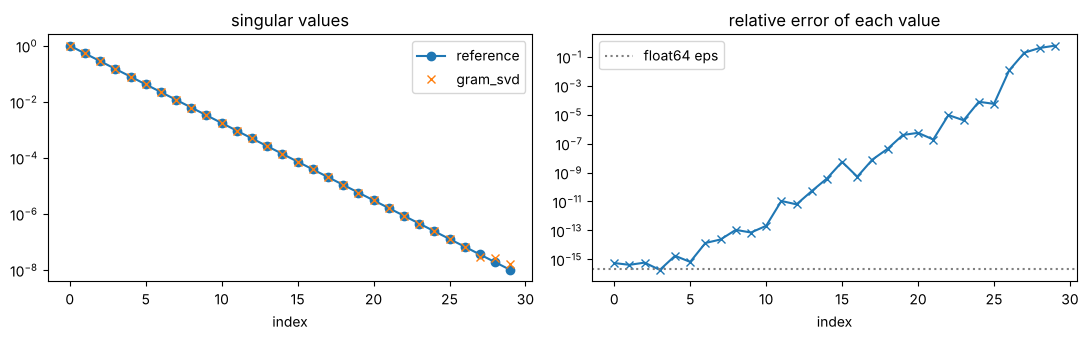

In [4]:
import matplotlib.pyplot as plt
from svdlab import MatrixCase

case = MatrixCase.create(m=40, n=30, family='geometric', condition=1e8, dtype='float64')
u_ref, s_ref, vh_ref = case.reference[0]          # LAPACK gesvd of the exact input, in FP64
u, s, vh = gram_svd(case.tensor(DEVICE), 30)
s = s.cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogy(s_ref, 'o-', label='reference')
ax[0].semilogy(s, 'x', label='gram_svd')
ax[0].set_title('singular values'); ax[0].set_xlabel('index'); ax[0].legend()
ax[1].semilogy(abs(s - s_ref) / s_ref, 'x-')
ax[1].axhline(2.2e-16, color='gray', ls=':', label='float64 eps')
ax[1].set_title('relative error of each value'); ax[1].set_xlabel('index'); ax[1].legend()
plt.tight_layout()

### How to debug your own failing case

- `svdlab.check(fn, [one_case_dict])` (or `--case NAME` on the command line) runs a single
  matrix.
- `repeat=1, warmup=0` (`--repeat 1 --warmup 0`) skips the repeated timing calls.
- Put `breakpoint()` inside your function. It stops there with the real test matrix in `a`.
  This works best from a terminal: `python -m svdlab check my_svd.py --case NAME`.
- An exception inside your function marks that case `ERROR` with the message, and the other
  cases still run.

## Step 5. The fix

Keep the fast Gram step, but don't trust its eigenvectors to full precision. Use them only
as a starting basis V₀. The columns of A V₀ are then *almost* orthogonal, and a one-sided
Jacobi SVD, which is very accurate, finishes the job in very few sweeps. It is ready-made
as `svdlab.blocks.jacobi_svd` (notebook 3 lists all such blocks).

The function also shows a common way to handle wide matrices. Factorize the tall adjoint
aᴴ = U' s V'ᴴ, then a = V' s U'ᴴ, so return `(V', s, U'ᴴ)`. Many algorithms are simpler to
write for tall matrices only.

**What this cell does:** it defines `refined` and compares it on the quick suite with
`gram_svd` and with the Jacobi starter from notebook 1 (given as a file name).

**What you should see:** `gram_svd` 4/6, `refined` 6/6 and `jacobi_starter` 6/6, with
`refined` faster than the plain Jacobi starter.

In [5]:
from svdlab import blocks

def refined(a, rank):
    """Gram eigenvectors as a starting basis, then Jacobi on A V to repair the accuracy."""
    wide = a.shape[0] < a.shape[1]
    x = a.mH if wide else a                        # work on a tall matrix
    _, v = torch.linalg.eigh(x.mH @ x)
    u, s, wh = blocks.jacobi_svd(x @ v)            # x V = U diag(s) Wᴴ, so x = U diag(s) (V W)ᴴ
    vh = wh @ v.mH
    u, s, vh = u[:, :rank], s[:rank], vh[:rank]
    return (vh.mH, s, u.mH) if wide else (u, s, vh)  # wide input: a = (aᴴ)ᴴ, swap the factors

rows = svdlab.compare({'gram_svd': gram_svd, 'refined': refined, 'jacobi_starter': 'examples/my_svd.py'},
                      svdlab.QUICK_SUITE, device=DEVICE, verbose=False)
for s in svdlab.summary(rows):
    print(f"{s['method']:<15} {s['ok']}/{s['cases']} ok   total {s['total_median_ms']:8.2f} ms   "
          f"failed: {', '.join(s['failed_cases']) or '-'}")

gram_svd        4/6 ok   total     1.01 ms   failed: ill_conditioned_1e8, clustered
refined         6/6 ok   total   319.08 ms   failed: -
jacobi_starter  6/6 ok   total   669.04 ms   failed: -


Both functions are also in [examples/gram_svd.py](../examples/gram_svd.py), so you can run
the same comparison from a terminal:

```bash
python -m svdlab check examples/gram_svd.py --quick                 # the function svd (= gram_svd): 4/6 ok
python -m svdlab check examples/gram_svd.py:refined --quick         # file.py:function picks another function
```

## Step 6. Your turn

**What this cell does:** it holds a method for you to replace. It starts as a working
method (QR first, then the library SVD of the small factor R) so the notebook runs from top
to bottom. Replace the body with your own algorithm and run the cell again. It is compared
with `torch` on the quick suite.

In [6]:
def my_svd(a, rank):
    """YOUR CODE HERE. Starter: a = Q R, then the SVD of the small R."""
    wide = a.shape[0] < a.shape[1]
    x = a.mH if wide else a
    q, r = torch.linalg.qr(x)                      # x = Q R, R is n x n
    ur, s, vh = torch.linalg.svd(r)                # R = Ur diag(s) Vh
    u = q @ ur                                     # so x = (Q Ur) diag(s) Vh
    u, s, vh = u[:, :rank], s[:rank], vh[:rank]
    return (vh.mH, s, u.mH) if wide else (u, s, vh)

rows = svdlab.compare({'my_svd': my_svd, 'torch': 'torch'}, svdlab.QUICK_SUITE, device=DEVICE)

my_svd               gaussian_tall          ok       0.259 ms  recon 1.55e-15  tail× -  σ-rel 1.78e-15  orth 1.23e-15


my_svd               gaussian_wide          ok       0.165 ms  recon 2.59e-15  tail× -  σ-rel 2.78e-15  orth 1.53e-15


my_svd               ill_conditioned_1e8    ok       0.186 ms  recon 4.55e-15  tail× -  σ-rel 2.04e-10  orth 1.14e-15


my_svd               clustered              ok       7.974 ms  recon 1.68e-15  tail× -  σ-rel 6.07e-15  orth 1.21e-15


my_svd               complex_gaussian       ok       0.561 ms  recon 2.64e-15  tail× -  σ-rel 1.99e-15  orth 1.76e-15


my_svd               low_rank_k4            ok       0.448 ms  recon 6.64e-06  tail× 1.00e+00  σ-rel 7.18e-16  orth 7.52e-16


torch                gaussian_tall          ok       0.258 ms  recon 1.55e-15  tail× -  σ-rel 1.78e-15  orth 1.23e-15


torch                gaussian_wide          ok       0.115 ms  recon 1.66e-15  tail× -  σ-rel 1.44e-15  orth 1.29e-15


torch                ill_conditioned_1e8    ok       0.189 ms  recon 4.40e-15  tail× -  σ-rel 2.10e-10  orth 1.49e-15
torch                clustered              ok       0.139 ms  recon 2.65e-15  tail× -  σ-rel 2.26e-14  orth 1.36e-15


torch                complex_gaussian       ok       0.138 ms  recon 2.34e-15  tail× -  σ-rel 1.33e-15  orth 1.23e-15
torch                low_rank_k4            ok       0.263 ms  recon 6.64e-06  tail× 1.00e+00  σ-rel 5.55e-16  orth 5.09e-16


**What this cell does:** once all quick cases pass, it runs the standard set of eight larger
matrices (`DEFAULT_SUITE`, up to 400×300, including a sparse and a float32 one). That is
the set to report results on. A slow Python method can take a while here.

In [7]:
rows = svdlab.check(my_svd, svdlab.DEFAULT_SUITE, device=DEVICE)

my_svd               gaussian_tall          ok       2.687 ms  recon 2.18e-15  tail× -  σ-rel 4.38e-15  orth 1.85e-15


my_svd               gaussian_wide          ok       3.075 ms  recon 2.50e-15  tail× -  σ-rel 4.15e-15  orth 1.86e-15


my_svd               ill_conditioned_1e8    ok       2.429 ms  recon 1.62e-15  tail× -  σ-rel 9.17e-10  orth 1.68e-15


my_svd               clustered              ok       2.602 ms  recon 1.80e-15  tail× -  σ-rel 1.63e-14  orth 1.87e-15


my_svd               sparse_dense_storage   ok       5.198 ms  recon 2.40e-15  tail× -  σ-rel 4.61e-15  orth 2.19e-15


my_svd               complex_gaussian       ok       2.773 ms  recon 2.22e-15  tail× -  σ-rel 3.73e-15  orth 1.87e-15


my_svd               low_rank_k10           ok       4.366 ms  recon 8.75e-06  tail× 1.00e+00  σ-rel 1.39e-15  orth 1.09e-15


my_svd               low_rank_k16_fp32      ok      11.396 ms  recon 8.70e-04  tail× 1.00e+00  σ-rel 2.18e-06  orth 1.88e-06


## Step 7. From the notebook to a file

To share your method or check it from the command line, put it in a `.py` file with a
function named `svd`.

**What these cells do:** the first creates the folder `laboratory_runs/` (git ignores it, so
nothing you write there gets committed by accident). The second writes the method to a file
with the `%%writefile` cell magic. The third defines the terminal helper, and the fourth
checks the file exactly as a terminal would.

**What you should see:** `Writing laboratory_runs/my_svd.py`, then a report with 6/6 ok and
`exit code: 0`.

In [8]:
Path('laboratory_runs').mkdir(exist_ok=True)

In [9]:
%%writefile laboratory_runs/my_svd.py
import torch


def svd(a, rank):
    wide = a.shape[0] < a.shape[1]
    x = a.mH if wide else a
    q, r = torch.linalg.qr(x)
    ur, s, vh = torch.linalg.svd(r)
    u = q @ ur
    u, s, vh = u[:, :rank], s[:rank], vh[:rank]
    return (vh.mH, s, u.mH) if wide else (u, s, vh)

Writing laboratory_runs/my_svd.py


In [10]:
import shlex
from svdlab.__main__ import main as svdlab_main

def svdlab_cli(command):
    """Run `python -m svdlab <command>` inside this notebook (same output, same exit code)."""
    code = svdlab_main(shlex.split(command))
    print(f'exit code: {code}')

In [11]:
svdlab_cli(f'check laboratory_runs/my_svd.py --quick --device {DEVICE}')

recon  = |A - U diag(s) Vh| / |A|          tail× = recon / best possible (truncated cases)
σ-rel  = max relative error of the values   orth  = max(|UᴴU - I|, |V Vᴴ - I|) / sqrt(k)
ok     = orth and recon within 100·eps·max(m, n), or tail× <= 1.05



my_svd               gaussian_tall          ok       0.868 ms  recon 1.55e-15  tail× -  σ-rel 1.78e-15  orth 1.23e-15


my_svd               gaussian_wide          ok       0.185 ms  recon 2.59e-15  tail× -  σ-rel 2.78e-15  orth 1.53e-15


my_svd               ill_conditioned_1e8    ok       0.275 ms  recon 4.55e-15  tail× -  σ-rel 2.04e-10  orth 1.14e-15


my_svd               clustered              ok       0.533 ms  recon 1.68e-15  tail× -  σ-rel 6.07e-15  orth 1.21e-15


my_svd               complex_gaussian       ok       0.330 ms  recon 2.64e-15  tail× -  σ-rel 1.99e-15  orth 1.76e-15


my_svd               low_rank_k4            ok       1.219 ms  recon 6.64e-06  tail× 1.00e+00  σ-rel 7.18e-16  orth 7.52e-16

my_svd: 6/6 ok, total median 3.409 ms
exit code: 0


## Summary

- Smoke-test on one matrix, then run the quick suite, then the default suite.
- A small `recon` is not enough: orthogonality matters, and the checker tests it.
- Squaring the matrix (AᴴA) is fast but loses accuracy on ill-conditioned and clustered
  spectra. A short Jacobi pass repairs it.
- `file.py:function` checks any function in a file.

## Next

[03_blocks_and_recipes.ipynb](03_blocks_and_recipes.ipynb): instead of writing everything,
replace one step of an existing SVD.